In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
TASK = Path.cwd().parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK/'input', TASK/'output'
CONFIG = json.loads((ROOT/'config.json').read_text())
EPS, Y, SEED = CONFIG['eps'], CONFIG['last_year'], CONFIG['seed']

In [3]:
sns.set_theme(style='whitegrid',context='notebook',palette='colorblind')
SELECTED = CONFIG['models']
ORDER = ['empirical_complete'] + SELECTED
PALETTE = dict(zip(ORDER,sns.color_palette('colorblind',len(ORDER))))
DASHES = dict(zip(ORDER,['',(4,2),(1,1),(6,2,1,2),(3,1,1,1),(8,2)]))
MARKERS = dict(zip(ORDER,['o','s','^','D','v','P']))
def save(fig,name):
    fig.tight_layout()
    fig.savefig(OUTPUT/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(OUTPUT/(name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
def lines(data,x,y,ax):
    sns.lineplot(data=data,x=x,y=y,hue='source',style='source',hue_order=ORDER,style_order=ORDER,
                 palette=PALETTE,dashes=DASHES,markers=MARKERS,markersize=3,errorbar=None,ax=ax)
def legend(ax):
    ax.legend(fontsize=7,ncol=2)
def cdf_lines(data,x,y,ax):
    # duplicate x values draw vertical jumps; no averaging of left/right ECDF limits
    for source in ORDER:
        d = data.loc[data.source.eq(source)].sort_values(x,kind='stable')
        sns.lineplot(data=d,x=x,y=y,estimator=None,sort=False,color=PALETTE[source],
                     linestyle='-' if not DASHES[source] else (0,DASHES[source]),label=source,ax=ax)
    ax.set_ylim(-.02,1.02)

In [4]:
dropout = pd.read_csv(INPUT/'dropout_by_productivity.csv',dtype={'stage':str})
memory = pd.read_csv(INPUT/'conditional_memory.csv')
# both summaries use all observed empirical follow-up rather than complete survivors
ORDER = ['empirical_available'] + SELECTED
PALETTE = dict(zip(ORDER,sns.color_palette('colorblind',len(ORDER))))
DASHES = dict(zip(ORDER,['',(4,2),(1,1),(6,2,1,2),(3,1,1,1),(8,2)]))
MARKERS = dict(zip(ORDER,['o','s','^','D','v','P']))

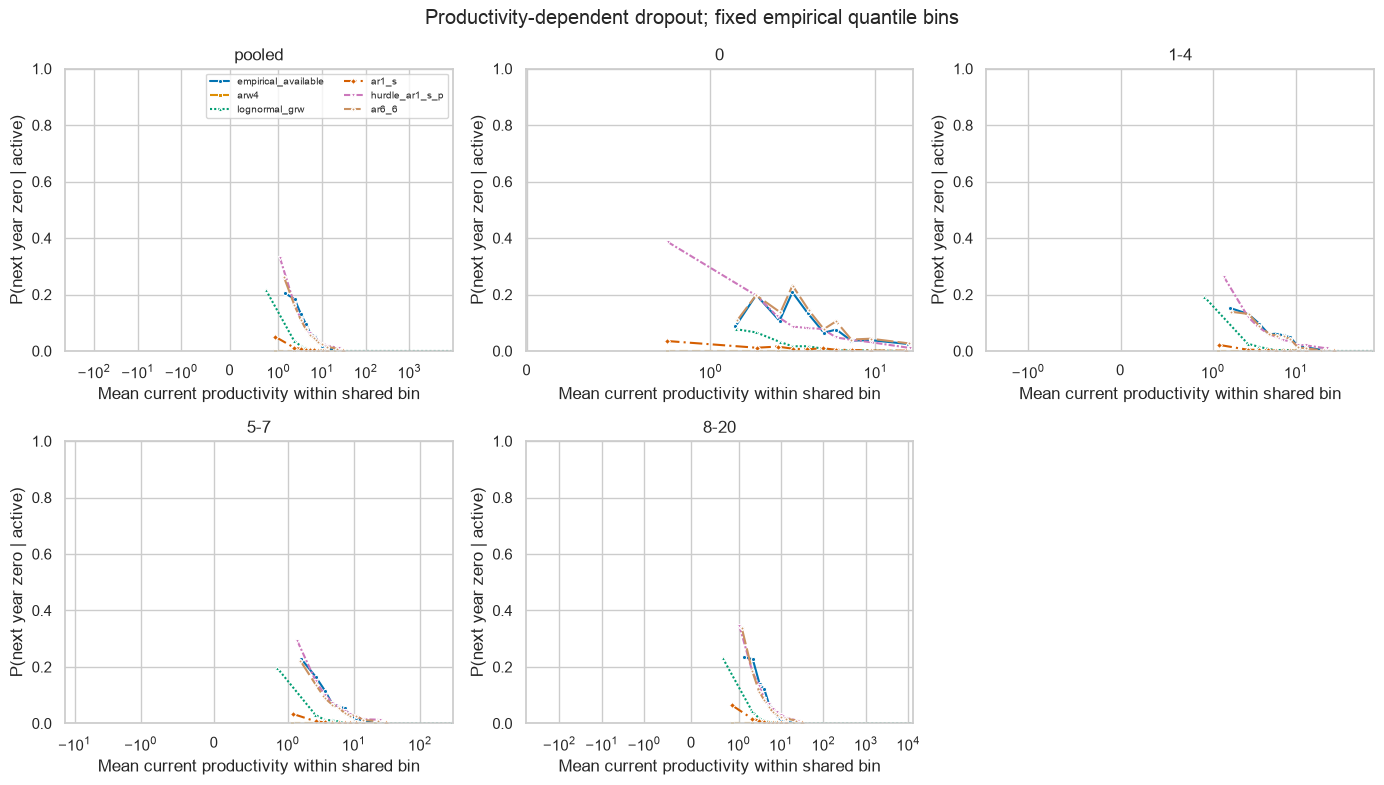

In [5]:
fig,axes = plt.subplots(2,3,figsize=(14,8))
for ax,stage in zip(axes.flat,['pooled','0','1-4','5-7','8-20']):
    lines(dropout.loc[dropout.stage.eq(stage)],'q_mean','probability',ax)
    ax.set(xlabel='Mean current productivity within shared bin',ylabel='P(next year zero | active)',title=stage,ylim=(0,1))
    ax.set_xscale('symlog',linthresh=1)
    if ax!=axes.flat[0]:ax.legend().remove()
axes.flat[-1].axis('off')
legend(axes.flat[0])
fig.suptitle('Productivity-dependent dropout; fixed empirical quantile bins')
save(fig,'dropout_productivity_stagewise')

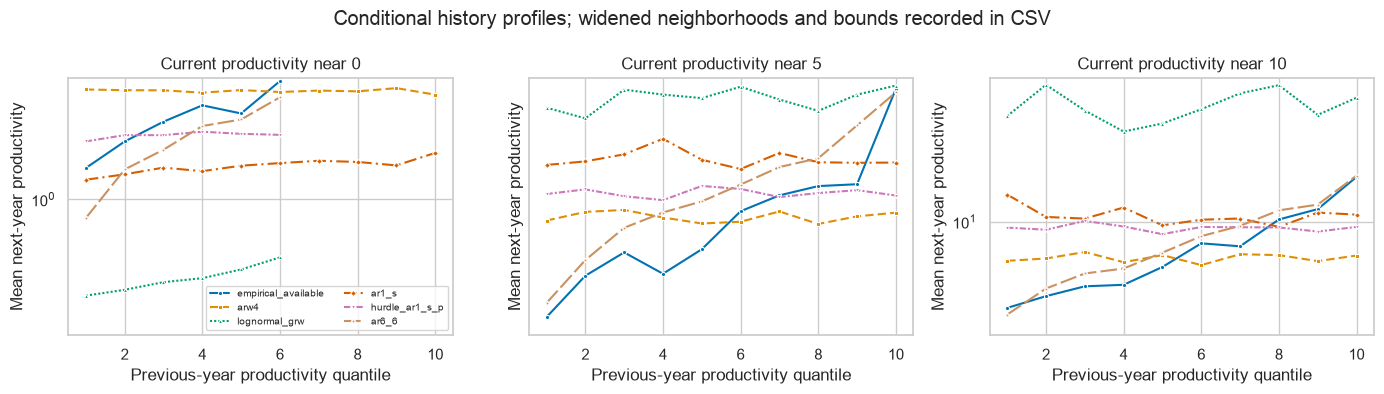

In [6]:
fig,axes = plt.subplots(1,3,figsize=(14,4))
for ax,target in zip(axes,[0,5,10]):
    lines(memory.loc[memory.target.eq(target)],'bin','next_mean',ax)
    ax.set(xlabel='Previous-year productivity quantile',ylabel='Mean next-year productivity',title=f'Current productivity near {target}')
    ax.set_yscale('symlog',linthresh=1)
    if ax!=axes[0]:ax.legend().remove()
legend(axes[0])
fig.suptitle('Conditional history profiles; widened neighborhoods and bounds recorded in CSV')
save(fig,'conditional_history_profiles')